# 02: Data audit

A look at `data/processed/positions.parquet` before any modelling decision is made: is the table
structurally sound, what is missing and why, how rare the target is, and how it moves with the
features the model will see. Nothing here changes the data; preprocessing is the next notebook.

The table has one row per ply. Each row describes the position **before** a move, the move's
think time, and the engine's judgement of that move. Column definitions and the blunder rule are in
[`data/README.md`](../data/README.md).

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from chess_blunder import config

pd.set_option('display.width', 120)
FIG_DIR = config.REPORTS_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

positions = pd.read_parquet(config.PROCESSED_DIR / 'positions.parquet')
games = pd.read_csv(config.PROCESSED_DIR / 'games_index.csv', parse_dates=['end_time'])
print(f'positions : {len(positions):,} rows x {positions.shape[1]} columns')
print(f'games     : {positions.game_id.nunique():,}')

positions : 260,030 rows x 25 columns
games     : 4,008


## 1. Structural checks

The positions table should agree with the game index exactly: every in-scope game present, one
row per ply, plies numbered 1..n with no gaps. A game that silently failed labelling would show up
here as a missing or short game.

In [2]:
plies_per_game = positions.groupby('game_id').size()
expected = games.set_index('game_id').plies

assert set(plies_per_game.index) == set(expected.index), 'games missing from positions'
assert (plies_per_game == expected.loc[plies_per_game.index]).all(), 'ply count differs from index'
assert not positions.duplicated(['game_id', 'ply']).any(), 'duplicate (game_id, ply)'
assert positions.groupby('game_id').ply.apply(
    lambda s: (s.to_numpy() == np.arange(1, len(s) + 1)).all()
).all(), 'gap in ply numbering'

print(f'{len(plies_per_game)} games, every one complete')
print(f'plies per game: min {plies_per_game.min()}, median {plies_per_game.median():.0f}, max {plies_per_game.max()}')

4008 games, every one complete
plies per game: min 1, median 61, max 206


## 2. Missing values

Only two columns have gaps, and both are missing by construction rather than by accident.

In [3]:
missing = positions.isna().sum()
missing[missing > 0].to_frame('missing rows')

,missing rows
seconds_spent,8015
my_rating_pre,42
mate_sequence,253868


In [4]:
first_moves = positions.groupby(['game_id', 'mover']).ply.transform('min') == positions.ply
spent_missing = positions.seconds_spent.isna()
print(f'seconds_spent missing      : {spent_missing.sum():,}')
print(f'  ...on a first move       : {(spent_missing & first_moves).sum():,}')
print(f'  ...anywhere else         : {(spent_missing & ~first_moves).sum():,}')

rating_missing = positions[positions.my_rating_pre.isna()]
print(f'my_rating_pre missing      : {len(rating_missing)} rows in {rating_missing.game_id.nunique()} game(s)')
print(f'  ...is it the first game? : {rating_missing.end_time.min() == positions.end_time.min()}')

seconds_spent missing      : 8,015
  ...on a first move       : 8,015
  ...anywhere else         : 0
my_rating_pre missing      : 42 rows in 1 game(s)
  ...is it the first game? : True


- **`seconds_spent`** is missing on each side's first move of every game (4,008 games × 2 sides,
  less one game too short for both sides to move). Chess.com's first clock comment for a colour is
  unreliable, so the think time is left missing rather than guessed, see `think_time` in
  `src/chess_blunder/features.py`. The column is excluded from the predictive model anyway (section
  6), so this matters only for the secondary question.
- **`my_rating_pre`** is missing for the very first game in the dataset, which has no previous game
  to take a rating from. One game out of 4,008: dropping it or imputing it changes nothing.
- **`mate_sequence`** is also null on most rows, but that is its meaning, not a gap: it names the
  mate rule that applied and is null when none did.

## 3. The target

Blunders are a minority class, so the base rate sets what a useless model scores and rules out
accuracy as a metric.

In [5]:
rate = positions.is_blunder.mean()
print(f'blunders  : {positions.is_blunder.sum():,} of {len(positions):,} moves ({rate:.2%})')
print(f'accuracy of always predicting "not a blunder": {1 - rate:.2%}')

positions.groupby('is_my_move').is_blunder.agg(rate='mean', moves='size').rename(
    index={True: 'my moves', False: 'opponent moves'}
)

blunders  : 23,843 of 260,030 moves (9.17%)
accuracy of always predicting "not a blunder": 90.83%


,rate,moves
is_my_move,,
opponent moves,0.091628,129982
my moves,0.091758,130048


My moves and my opponents' moves blunder at almost exactly the same rate. That is expected rather
than surprising: Chess.com pairs me with opponents of similar rating, so both sides are drawn from
roughly the same skill band.

### How the blunder rule contributes

Most blunders come from the winning-chances drop; a minority come from the two mate rules. A mate
transition that neither rule judges (a mate getting longer, a lost position staying lost) is never
a blunder.

In [6]:
source = np.select(
    [positions.mate_sequence.eq('mate_created'), positions.mate_sequence.eq('mate_lost'), positions.mate_involved],
    ['mate created', 'mate lost', 'mate, no judgement'],
    default='winning-chances drop',
)
positions.groupby(source).is_blunder.agg(blunders='sum', moves='size', rate='mean').sort_values('blunders', ascending=False)

,blunders,moves,rate
winning-chances drop,22207,240402,0.092374
mate created,1084,3934,0.275547
mate lost,552,2228,0.247756
"mate, no judgement",0,13466,0.000000


### Sensitivity to the threshold

The 15-point threshold is Lichess's, but it is still a choice. Rebuilding the label at 10 and 20
points shows how far the base rate moves with it. The mate rules do not use the threshold, so mate
moves keep their label.

The rebuild at 15 points matches the stored label on all but a handful of rows: `win_loss` is stored
rounded to two decimals, so a drop of 14.996 reads as 15.00 here but was judged a non-blunder.

In [7]:
def label_at(threshold):
    return np.where(positions.mate_involved, positions.is_blunder, positions.win_loss >= threshold)

rebuilt = label_at(15)
print(f'rebuilt label at 15 matches stored label on {(rebuilt == positions.is_blunder).mean():.4%} of rows '
      f'({(rebuilt != positions.is_blunder).sum()} differ)')

pd.DataFrame(
    {t: {'blunder rate': label_at(t).mean(), 'blunders': int(label_at(t).sum())} for t in (10, 15, 20)}
).T.rename_axis('threshold (points)')

rebuilt label at 15 matches stored label on 99.9977% of rows (6 differ)


,blunder rate,blunders
threshold (points),,
10,0.131519,34199.0
15,0.091716,23849.0
20,0.067738,17614.0


## 4. Blunders per game

Blunders are not spread evenly: they cluster within games, partly because one blunder tends to leave
a sharp position that invites another. That clustering is the reason the evaluation must split by
game rather than by row (section 7).

games with no blunder : 2.3%
median per game       : 5
mean per game         : 5.95


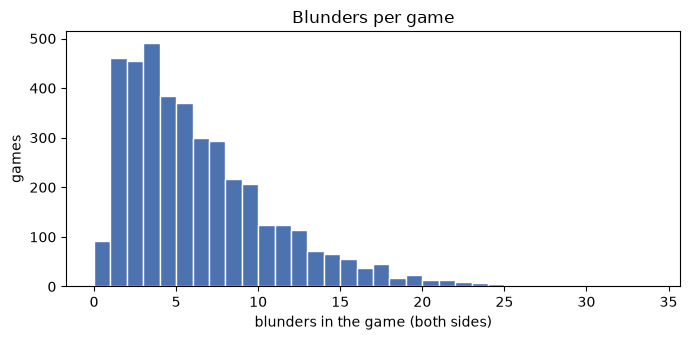

In [8]:
per_game = positions.groupby('game_id').is_blunder.sum()
print(f'games with no blunder : {(per_game == 0).mean():.1%}')
print(f'median per game       : {per_game.median():.0f}')
print(f'mean per game         : {per_game.mean():.2f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(per_game, bins=range(0, per_game.max() + 2), color='#4c72b0', edgecolor='white')
ax.set(xlabel='blunders in the game (both sides)', ylabel='games', title='Blunders per game')
fig.tight_layout()
fig.savefig(FIG_DIR / '02_blunders_per_game.png', dpi=150)

## 5. Blunder rate against the candidate features

Each panel bins one feature and plots the blunder rate per bin, with the overall base rate as a
dashed line. These are single-feature views, so they show association, not cause: the clock features
in particular are tangled up with how complicated the position is.

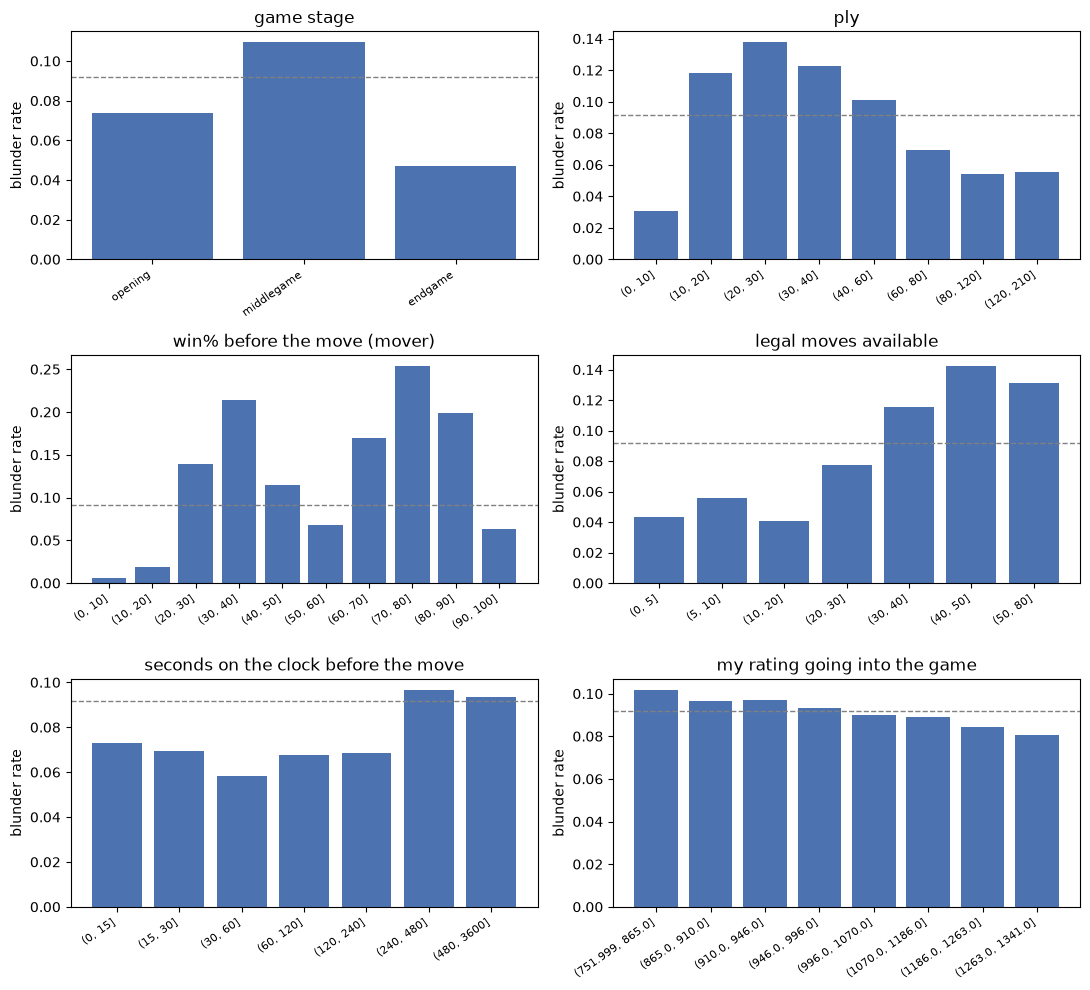

In [9]:
def rate_by(series, bins=None, q=None):
    grouped = series
    if bins is not None:
        grouped = pd.cut(series, bins)
    elif q is not None:
        grouped = pd.qcut(series, q, duplicates='drop')
    return positions.groupby(grouped, observed=True).is_blunder.agg(rate='mean', moves='size')

panels = {
    'game stage': positions.groupby('game_stage').is_blunder.agg(rate='mean', moves='size')
                  .reindex(['opening', 'middlegame', 'endgame']),
    'ply': rate_by(positions.ply, bins=[0, 10, 20, 30, 40, 60, 80, 120, 210]),
    'win% before the move (mover)': rate_by(positions.win_before, bins=np.arange(0, 101, 10)),
    'legal moves available': rate_by(positions.legal_moves, bins=[0, 5, 10, 20, 30, 40, 50, 80]),
    'seconds on the clock before the move': rate_by(positions.seconds_before, bins=[0, 15, 30, 60, 120, 240, 480, 3600]),
    'my rating going into the game': rate_by(positions.my_rating_pre, q=8),
}

fig, axes = plt.subplots(3, 2, figsize=(11, 10))
for ax, (name, table) in zip(axes.flat, panels.items()):
    ax.bar(range(len(table)), table.rate, color='#4c72b0')
    ax.axhline(rate, ls='--', c='grey', lw=1)
    ax.set_xticks(range(len(table)), [str(i) for i in table.index], rotation=35, ha='right', fontsize=8)
    ax.set(title=name, ylabel='blunder rate')
fig.tight_layout()
fig.savefig(FIG_DIR / '02_rate_by_feature.png', dpi=150)

In [10]:
for name, table in panels.items():
    print(f'--- {name}')
    print(table.assign(rate=table.rate.round(3)).to_string())

--- game stage
             rate   moves
game_stage               
opening     0.074   78769
middlegame  0.109  152439
endgame     0.047   28822
--- ply
             rate  moves
ply                     
(0, 10]     0.030  39864
(10, 20]    0.118  38905
(20, 30]    0.138  36655
(30, 40]    0.123  33148
(40, 60]    0.101  51663
(60, 80]    0.069  30367
(80, 120]   0.054  24418
(120, 210]  0.056   5010
--- win% before the move (mover)
             rate  moves
win_before              
(0, 10]     0.006  41657
(10, 20]    0.019  15242
(20, 30]    0.139   8453
(30, 40]    0.214  10755
(40, 50]    0.115  43033
(50, 60]    0.068  48258
(60, 70]    0.170  13775
(70, 80]    0.254  10192
(80, 90]    0.198  17463
(90, 100]   0.063  51202
--- legal moves available
              rate  moves
legal_moves              
(0, 5]       0.044  25068
(5, 10]      0.055   7892
(10, 20]     0.041  27846
(20, 30]     0.078  71507
(30, 40]     0.116  94266
(40, 50]     0.142  30850
(50, 80]     0.131   2601
--- 

What stands out to me:

- **Middlegame is what messes me up** (10.9%, against 7.4% in the opening and 4.7% in the endgame). By
  ply, the first ten plies almost never contain a blunder (3.0%) and the rate peaks at plies 20–30
  (13.8%), then falls as games simplify which makes sense.
- **More legal moves = more blunders.** The rate climbs from about 4–5% with 20 or fewer legal moves to
  14% with 40–50: more options means more ways to go wrong.
- **Win% before the move is strongly non-linear, with two peaks.** The rate is near zero in positions
  that are already lost (under 20%), where there is nothing left to throw away on the winning-chances scale, and it is low again once a position is won (over 90%). It peaks at 30–40% and 70–80%, where the curve is
  steepest, and dips around 50%, partly because most level positions are early-opening ones. A linear
  model cannot represent this shape from the raw column; it will need binning or a flexible model.
- **The clock before the move shows no time-trouble effect.** Moves made with under a minute left are,
  if anything, *less* likely to be blunders (6–7%). Very few moves are made that low (about 6,000 of
  260,000), and by then many positions are already decided. `seconds_before` is a legitimate input,
  but on its own it is weak.
- **Rating has a small, steady effect:** 10.2% in the lowest-rated eighth of moves down to 8.1% in
  the highest. It reflects one player improving over four years, so it overlaps heavily with time
  (section 6).

### Think time (the secondary question)

`seconds_spent` is how long the move took. It is not available before the move is made, so it is
never a model input, but it is the variable the secondary question is about. A first descriptive
look:

In [11]:
spent = rate_by(positions.seconds_spent, bins=[0, 1, 2, 5, 10, 20, 40, 400])
print(spent.assign(rate=spent.rate.round(3)).to_string())

                rate  moves
seconds_spent              
(0, 1]         0.036   9255
(1, 2]         0.045  34516
(2, 5]         0.071  76561
(5, 10]        0.102  62179
(10, 20]       0.136  45216
(20, 40]       0.162  19425
(40, 400]      0.186   4863


The longer a move took, the more likely it is a blunder: 3.6% for moves under a second, rising
steadily to 18.6% for moves over 40 seconds. Reading this as "play faster" would be wrong. A long
think is a sign that the position is hard, and hard positions produce blunders whatever the clock
says; the fastest moves are mostly recaptures and book moves with one obvious answer. Separating the
two needs a model that controls for position difficulty, which is Milestone 3's job.

## 6. Drift over time

The data covers four years of one player's games. If the blunder rate moves over that time, a test
set made of the most recent games will have a different base rate to the training set, which is
exactly the situation the model would face in use, but it must be reported.

In [12]:
by_year = positions.groupby(positions.end_time.dt.year).is_blunder.agg(rate='mean', moves='size')
by_year.assign(rate=by_year.rate.round(4))

,rate,moves
end_time,,
2022,0.0973,8598
2023,0.0969,114123
2024,0.0928,26716
2025,0.0882,58915
2026,0.0828,51678


The rate falls steadily, from 9.7% in 2022 to 8.3% in 2026. The model will be tested on the period
with the lowest rate (section 8: 9.4% in training, 8.3% in test), so precision on the test set will
be slightly lower than cross-validation on the training years suggests. That is a reason to report
the test-set base rate next to every metric.

## 7. Which columns may be used

Columns are sorted by **when they become known**. The task is to predict a blunder before the move
is played, so anything only known after the move is leakage.

In [13]:
roles = pd.DataFrame.from_records([
    ('game_id', 'identifier', 'grouping key for splits only'),
    ('ply', 'feature', 'known before the move'),
    ('mover', 'feature', 'known before the move'),
    ('is_my_move', 'feature / filter', 'known before the move'),
    ('pieces_white', 'feature', 'position before the move'),
    ('pieces_black', 'feature', 'position before the move'),
    ('material_diff', 'feature', 'position before the move'),
    ('legal_moves', 'feature', 'position before the move'),
    ('game_stage', 'feature', 'position before the move'),
    ('seconds_before', 'feature', 'clock before the move'),
    ('my_rating_pre', 'feature', 'rating going into the game'),
    ('time_control', 'feature', 'known before the game'),
    ('eco', 'excluded', 'Chess.com assigns the opening after the game, from the whole move list'),
    ('end_time', 'split key', 'orders games for the time-based test set; not an input'),
    ('cp_before', 'feature', 'engine evaluation of the position before the move'),
    ('win_before', 'feature', 'engine evaluation of the position before the move'),
    ('seconds_spent', 'excluded (leakage)', 'think time on the move being predicted'),
    ('seconds_remaining', 'excluded (leakage)', 'clock after the move, = seconds_before - seconds_spent'),
    ('cp_after', 'excluded (leakage)', 'evaluation after the move; defines the label'),
    ('cp_loss', 'excluded (leakage)', 'derived from cp_after'),
    ('win_after', 'excluded (leakage)', 'evaluation after the move; defines the label'),
    ('win_loss', 'excluded (leakage)', 'the label is a threshold on this'),
    ('mate_sequence', 'excluded (leakage)', 'which mate rule judged the move'),
    ('mate_involved', 'excluded (leakage)', 'uses the position after the move'),
    ('is_blunder', 'target', ''),
], columns=['column', 'role', 'reason']).set_index('column')

assert set(roles.index) == set(positions.columns), 'audit table out of step with the data'
roles

,role,reason
column,,
game_id,identifier,grouping key for splits only
ply,feature,known before the move
mover,feature,known before the move
is_my_move,feature / filter,known before the move
pieces_white,feature,position before the move
pieces_black,feature,position before the move
material_diff,feature,position before the move
legal_moves,feature,position before the move
game_stage,feature,position before the move


Two of these deserve a note:

- **`cp_before` / `win_before`** need an engine to compute. Using them is legitimate and a real-time
  version would run the engine on the current position, but it means the model is predicting
  blunders *given an engine's view of the position* .
- **`eco`** looks like a pre-game fact but is not: Chess.com names the opening from the moves that
  were actually played, including moves after the one being predicted. Rather than reconstruct an
  opening name from only the moves so far, it is left out.

## 8. Evaluation design

Fixed here, before any model is fitted, and already recorded in `data/README.md`:

- **Test set:** the most recent 20% of games by `end_time`, held out until Milestone 3's final
  comparison. Splitting by time keeps every game's moves on one side of the split and mirrors use:
  train on past games, predict future ones.
- **Tuning:** 5-fold cross-validation grouped by `game_id` on the training games, so no game
  contributes moves to both a training fold and its validation fold (section 4 shows why that would
  flatter the scores).
- **Metrics:** precision–recall AUC as the primary metric, because the positive class is ~9% of moves
  and PR-AUC's floor is the base rate rather than 0.5. ROC-AUC alongside it for comparability, and
  the Brier score to check calibration, since the output is meant to be read as a risk.

In [14]:
order = games.sort_values('end_time').game_id.to_numpy()
cut = int(len(order) * 0.8)
test_games = set(order[cut:])
is_test = positions.game_id.isin(test_games)

split = positions.groupby(is_test.map({False: 'train', True: 'test'})).agg(
    games=('game_id', 'nunique'), moves=('ply', 'size'), blunder_rate=('is_blunder', 'mean'),
    first=('end_time', 'min'), last=('end_time', 'max'),
)
split.loc[['train', 'test']]

,games,moves,blunder_rate,first,last
game_id,,,,,
train,3206,205711,0.093962,2022-10-11 08:04:16+00:00,2025-11-17 08:09:35+00:00
test,802,54319,0.083102,2025-11-17 20:55:23+00:00,2026-09-30 07:02:45+00:00


## What this sets

- The positions table is complete: every in-scope game, every ply, no duplicates.
- The only missing values are explained by construction (first-move think time, first-game rating).
- The target is **~9.2% of moves**. A model that always says "no blunder" is ~91% accurate, which is
  why accuracy is not reported.
- The label's base rate is shown at 10, 15 and 20 points, so the effect of the threshold choice is on
  the record.
- Position complexity (game stage, ply, `legal_moves`) and the balance of the position
  (`win_before`) show clear association with blunders; `win_before`'s effect is strongly non-linear.
  Clock time before the move does not.
- Think time rises steadily with blunder rate, which is the confound the secondary question has to
  untangle.
- Eight columns are leakage and `eco` is excluded; the remaining features are all known before the
  move.
- The blunder rate drifts down over time, so the time-based test set has a lower base rate than the
  training games.

**Next:** `03_preprocessing_baseline.ipynb` builds the feature matrix from the columns marked
*feature* above, applies the split, and scores the baselines.